# Exercise 19 – Neighbour counts and k-means clustering

**Week 4 · Descriptors and unsupervised learning**

A more structural descriptor: the smallest and largest number of neighbours
(atoms within 1.5) that any atom in the cluster has. Instead of grouping by
hand, the **k-means** algorithm groups the clusters into $k$ groups in
descriptor space.

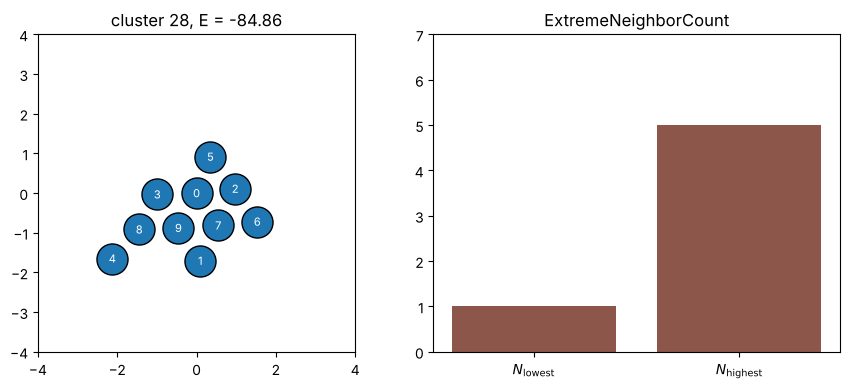

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from sklearn.cluster import KMeans

from comphy import DATA_DIR
from comphy.atoms import LennardJones
from comphy.clusters import draw_gallery, plot_cluster
from comphy.descriptors import ExtremeNeighborCount

raw = np.loadtxt(DATA_DIR / "lj10clusters.txt")
positions = raw.reshape(len(raw), -1, 2)
calc = LennardJones()
descriptor = ExtremeNeighborCount(cutoff=1.5)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_cluster(axes[0], positions[28], size=500)
axes[0].set(xlim=(-4, 4), ylim=(-4, 4), title=f"cluster 28, E = {calc.energy(positions[28]):.2f}")
descriptor.draw(axes[1], positions[28])
fig.tight_layout()
plt.show()

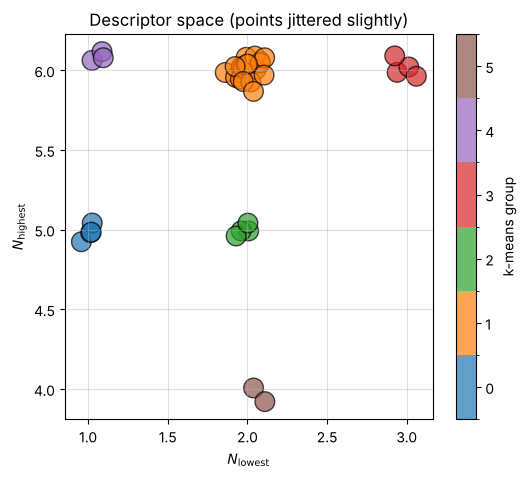

In [2]:
X = np.array([descriptor(p) for p in positions])
k = 6
labels = KMeans(n_clusters=k, n_init=10, random_state=20).fit_predict(X)
cmap = ListedColormap([f"C{i}" for i in range(k)])

fig, ax = plt.subplots(figsize=(6, 5))
jitter = np.random.default_rng(0).normal(0, 0.06, X.shape)     # separate overlapping points
sc = ax.scatter(*(X + jitter).T, c=labels, cmap=cmap,
                norm=BoundaryNorm(np.arange(-0.5, k), k), s=200, alpha=0.7, edgecolor="black")
cbar = fig.colorbar(sc, ax=ax, ticks=range(k))
cbar.set_label("k-means group")
ax.set(xlabel=r"$N_\mathrm{lowest}$", ylabel=r"$N_\mathrm{highest}$",
       title="Descriptor space (points jittered slightly)", aspect="equal")
ax.grid(True, alpha=0.4)
plt.show()

Because the descriptor only takes a few integer values, many clusters share
exactly the same point – k-means essentially groups the occupied grid points.

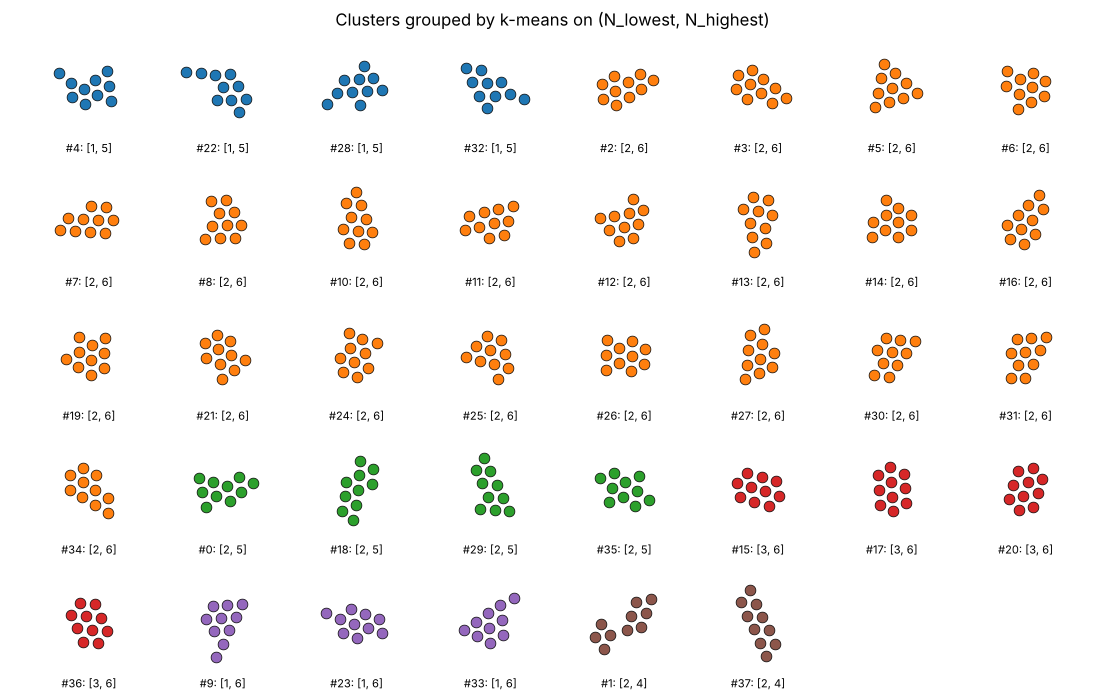

In [3]:
order = np.argsort(labels, kind="stable")
fig, ax = plt.subplots(figsize=(14, 9))
draw_gallery(ax, positions[order], colors=[f"C{labels[i]}" for i in order], ncols=8, size=60,
             labels=[f"#{i}: {X[i].tolist()}" for i in order])
ax.set_title("Clusters grouped by k-means on (N_lowest, N_highest)")
plt.show()